<a href="https://colab.research.google.com/github/remifakunle59-design/Forest-Carbon-Analysis/blob/main/Land_Cover_Change_and_Carbon_Stocks_reanalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question:**

    Which land use transitions majorly influenced forest loss?
    How did land use changes affected carbon stocks between 1985 and 2020?
    How does tree biomass differ between forests and plantation?

**Source data:** Forest Field Inventory (Table 4.7) and Land-Cover Areas (Table 4.2) from my MSc thesis

Pan African University Institute of Life and Earth Sciences (PAULESI).

## Data and method

1. **Forest Field Inventory:** 40 plots across six land use types were assessed within 3 carbon pools (aboveground, belowground and soil carbon (Mg C/ha)) (Table 4.7).

2. Soil samples for the **Soil carbon** analyses were taken in 3 depth (0-10, 10-20 and 20-30 cm) and summed up after laboratory analyses. (Table 4.6, Figure 4.13). The relative variation of SOC concentration (Table 4.11) and bulk density (Table 4.8) is estimated to lead to soil uncertainty.

3. **Land cover** for year  1985, to 2020 using 7 years interval were assessed to analyse land use/land cover changes in the area (Table 4.2),  producing carbon stocks at each map year.

4. **Upscaling:** carbon stock of a class is the multiplication of its area (ha) by mean carbon per hectare and the total stock were summed up.

**Assumptions**
- Oil Palm and Cocoa Plantations were the 2 most common plantation in the area. Hence they were combined together and formed the plantation land cover class. Similarly, cassava and maize farmlands formed the Cropland class.
- Urban, rock outcrop and water were simplified to be zero carbon.
- The standard error of the plot means were used to show the uncertainity.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
#Carbon_Stock_Across_6_land_use_types_within_3_carbon_pool
csv_text = """land_use_types,aboveground,belowground,soil
Dense Forest,116.88,27.47,9.91
Dense Forest,117.23,27.55,11.45
Dense Forest,120.95,28.42,15.5
Dense Forest,112.71,26.49,14.74
Dense Forest,118.72,27.9,11.8
Dense Forest,129.75,30.49,29.15
Light Forest,100.2,23.55,10.055
Light Forest,82.91,19.48,12.247
Light Forest,86.45,20.32,14.132
Light Forest,82.75,19.45,11.59
Light Forest,115.82,27.22,17.025
Light Forest,75.42,17.72,13.774
Oil Palm,72.8,17.11,8.64
Oil Palm,78.83,18.53,9.84
Oil Palm,71.95,16.91,7.17
Oil Palm,61.12,14.36,9.63
Oil Palm,53.59,12.59,7.55
Oil Palm,65.15,15.31,6.69
Oil Palm,55.43,13.03,7.42
Oil Palm,79.59,18.7,6.39
Cocoa,49.25,11.57,7.41
Cocoa,53.73,12.63,7.46
Cocoa,60.13,14.13,6.76
Cocoa,61.12,14.36,9.89
Cocoa,58.3,13.7,7.1
Cocoa,85.88,20.18,7.18
Cocoa,72.9,17.13,9
Cocoa,59.34,13.94,6.23
Cassava,17.77,4.18,7.89
Cassava,19.64,4.61,8.63
Cassava,20.99,4.93,9.07
Cassava,18.72,4.4,9.71
Cassava,15.93,3.74,6.92
Cassava,23.21,5.46,9.66
Maize,10.03,2.36,6.31
Maize,13.98,3.29,7.4
Maize,11.57,2.72,9.24
Maize,16.83,3.96,8.34
Maize,11.22,2.64,8.66
Maize,15.21,3.57,10.19
"""

plots = pd.read_csv(StringIO(csv_text))

order = ["Dense Forest", "Light Forest", "Oil Palm", "Cocoa", "Cassava", "Maize"]
n = plots["land_use_types"].value_counts().reindex(order)

# Aboveground and belowground carbon: mean and std from the plot values
ag = plots.groupby("land_use_types")["aboveground"].agg(["mean", "std"]).reindex(order)
bg = plots.groupby("land_use_types")["belowground"].agg(["mean", "std"]).reindex(order)

# Soil carbon, 0-30 cm (Mg C/ha)
soil_carbon = pd.Series([92.55, 83.82, 63.33, 61.02, 51.88, 50.15], index=order)

# Soil uncertainty:
soil_conc_mean = pd.Series([1.50, 1.40, 1.50, 1.35, 1.59, 1.77], index=order)
soil_conc_std   = pd.Series([0.48, 0.69, 0.53, 0.54, 0.76, 1.09], index=order)
BD_mean   = pd.Series([1.35, 1.44, 1.48, 1.51, 1.55, 1.58], index=order)
BD_std     = pd.Series([0.09, 0.10, 0.10, 0.08, 0.09, 0.08], index=order)
soil_std = soil_carbon * np.sqrt((soil_conc_std / soil_conc_mean) ** 2 + (BD_std / BD_mean) ** 2)

carbon = pd.DataFrame({
    "n": n,
    "aboveground": ag["mean"], "belowground": bg["mean"], "soil": soil_carbon,
})
carbon["total"] = carbon[["aboveground", "belowground", "soil"]].sum(axis=1)

# STD of the total:
carbon["total_std"] = np.sqrt(ag["std"] ** 2 + bg["std"] ** 2 + soil_std ** 2)

print("CARBON STOCK (Mg C/ha)")
print(carbon.round(1))

plots.to_csv("table_4_7_plots.csv", index=False)

CARBON STOCK (Mg C/ha)
              n  aboveground  belowground  soil  total  total_std
Dense Forest  6        119.4         28.1  92.6  240.0       30.8
Light Forest  6         90.6         21.3  83.8  195.7       44.4
Oil Palm      8         67.3         15.8  63.3  146.5       25.0
Cocoa         8         62.6         14.7  61.0  138.3       27.4
Cassava       6         19.4          4.6  51.9   75.8       25.1
Maize         6         13.1          3.1  50.2   66.4       31.1


## Carbon by pool and land use

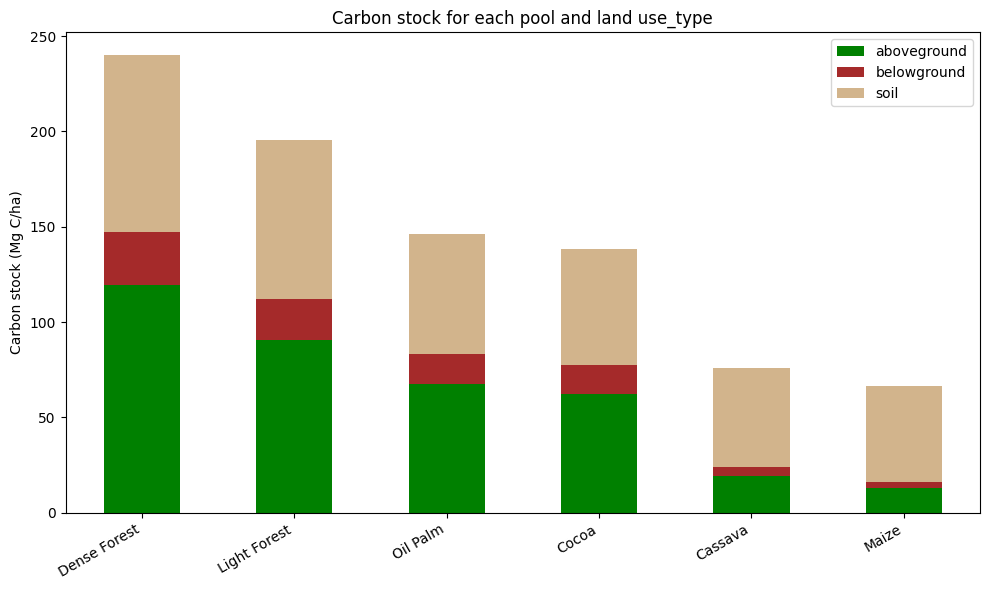

In [2]:
carbon[["aboveground", "belowground", "soil"]].plot(
    kind="bar", stacked=True, figsize=(10, 6),
    color=["green", "brown", "tan"]
)
plt.ylabel("Carbon stock (Mg C/ha)")
plt.title("Carbon stock for each pool and land use_type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Uncertainty

Standard Error was used to generate the total stock error bars combining the three pools while assumming that the pools vary independently.

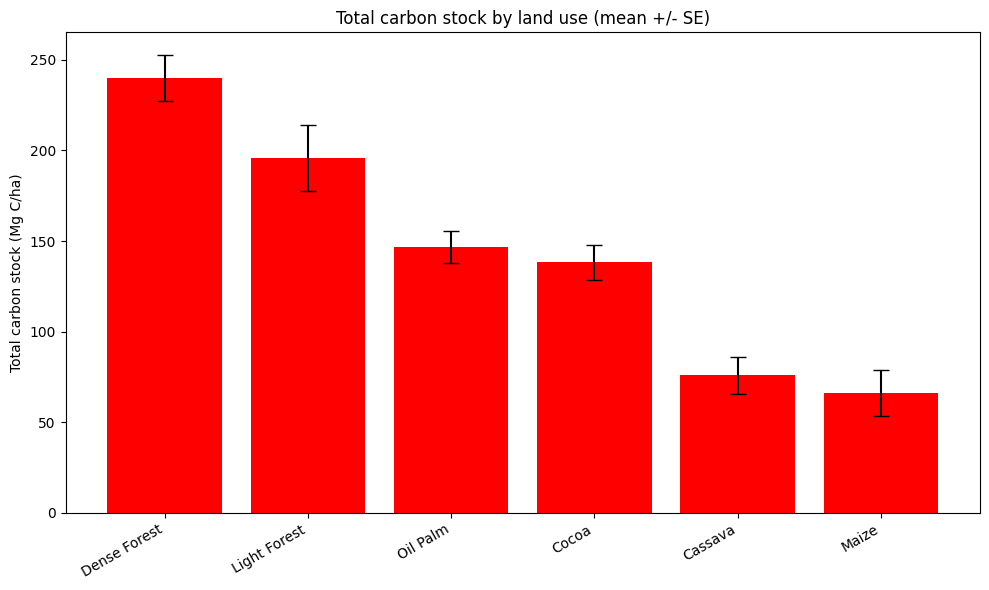

In [3]:
import numpy as np
import matplotlib.pyplot as plt

SE_total = carbon["total_std"] / np.sqrt(carbon["n"])

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(carbon.index, carbon["total"], yerr=SE_total, capsize=6, color="red")
ax.set_ylabel("Total carbon stock (Mg C/ha)")
ax.set_title("Total carbon stock by land use (mean +/- SE)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Land-cover change, 1985-2020

                1985    2020  change_km2  change_pct  share_1985_pct  \
Dense Forest  2491.0   592.6     -1898.4       -76.2            75.9   
Light Forest   296.3   650.3       354.0       119.5             9.0   
Plantation     354.5  1586.2      1231.7       347.5            10.8   
Cropland        40.2    68.0        27.8        69.1             1.2   
Urban Area      58.0   342.9       284.9       491.2             1.8   
Rock Outcrop    18.7    14.0        -4.7       -25.0             0.6   
Water Bodies    25.0    17.5        -7.5       -30.0             0.8   

              share_2020_pct  
Dense Forest            18.1  
Light Forest            19.9  
Plantation              48.5  
Cropland                 2.1  
Urban Area              10.5  
Rock Outcrop             0.4  
Water Bodies             0.5  


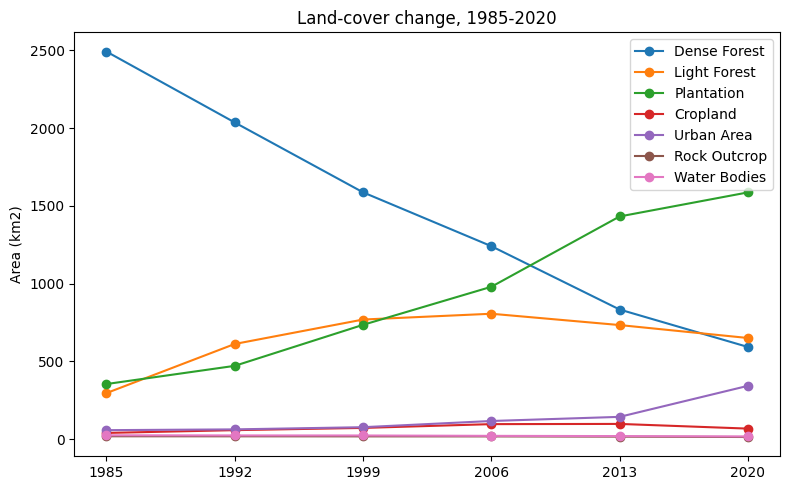

In [4]:
import pandas as pd
years = [1985, 1992, 1999, 2006, 2013, 2020]
area_km2 = {
    "Dense Forest": [2491.04, 2035.48, 1586.54, 1240.47, 833.29, 592.61],
    "Light Forest": [296.30, 611.99, 768.98, 806.25, 733.52, 650.32],
    "Plantation":   [354.46, 471.43, 734.98, 979.53, 1431.53, 1586.17],
    "Cropland":     [40.19, 58.06, 72.41, 96.81, 98.13, 67.98],
    "Urban Area":   [58.00, 63.05, 77.09, 116.93, 143.53, 342.92],
    "Rock Outcrop": [18.69, 18.44, 18.01, 17.86, 16.35, 14.01],
    "Water Bodies": [25.05, 24.09, 23.78, 21.42, 19.86, 17.54],
}
lulc = pd.DataFrame(area_km2, index=years).T

lulc["change_km2"] = lulc[2020] - lulc[1985]
lulc["change_pct"] = lulc["change_km2"] / lulc[1985] * 100
lulc["share_1985_pct"] = lulc[1985] / lulc[1985].sum() * 100
lulc["share_2020_pct"] = lulc[2020] / lulc[2020].sum() * 100

print(lulc[[1985, 2020, "change_km2", "change_pct",
            "share_1985_pct", "share_2020_pct"]].round(1))

lulc[years].T.plot(figsize=(8, 5), marker="o")
plt.ylabel("Area (km2)")
plt.title("Land-cover change, 1985-2020")
plt.tight_layout()
plt.show()

## Upscaling: carbon stock of the study area

Carbon stock of a class was derived by multiplying its area (ha) by the mean carbon per hectare. The uncertainty is the standard error of each class mean multiplied by its area, with classes combined in quadrature. Urban, rock and water are not included.

                mean     se
Dense Forest  239.98  12.58
Light Forest  195.70  18.13
Plantation    142.38   6.42
Cropland       71.10   7.91
      carbon_Tg  uncertainty_Tg
1985       70.9             3.2
1992       67.9             2.8
1999       64.1             2.5
2006       60.2             2.2
2013       55.4             1.9
2020       50.0             1.7
Change 1985-2020: -20.9 Tg C, -29.5 %


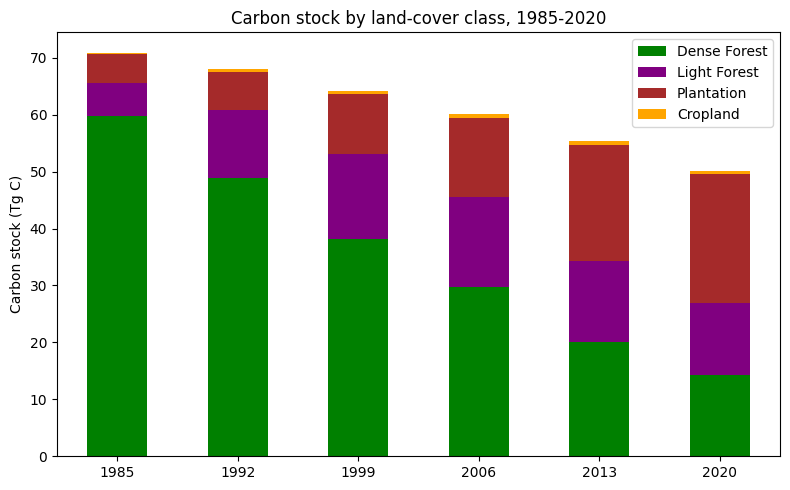

In [5]:
def pool(rows):
    # Combine classes: rows = [(n, mean, sd), ...] -> (n, mean, sd)
    N = sum(r[0] for r in rows)
    M = sum(r[0] * r[1] for r in rows) / N
    var = (sum((r[0] - 1) * r[2] ** 2 for r in rows)
           + sum(r[0] * (r[1] - M) ** 2 for r in rows)) / (N - 1)
    return N, M, np.sqrt(var)

def row(name):
    return (carbon.loc[name, "n"], carbon.loc[name, "total"], carbon.loc[name, "total_std"])

groups = {
    "Dense Forest": [row("Dense Forest")],
    "Light Forest": [row("Light Forest")],
    "Plantation":   [row("Oil Palm"), row("Cocoa")],
    "Cropland":     [row("Cassava"), row("Maize")],
}
stats = {}
for name, rows in groups.items():
    N, M, S = pool(rows)
    stats[name] = (M, S / np.sqrt(N))          # mean (Mg C/ha) and its standard error
stats = pd.DataFrame(stats, index=["mean", "se"]).T
print(stats.round(2))

classes = ["Dense Forest", "Light Forest", "Plantation", "Cropland"]
area_ha = lulc.loc[classes, years].T * 100          # km2 -> ha

stock = area_ha.mul(stats["mean"], axis=1) / 1e6    # Tg C (million tonnes)
err = area_ha.mul(stats["se"], axis=1) / 1e6

total = stock.sum(axis=1)
total_err = np.sqrt((err ** 2).sum(axis=1))

result = pd.DataFrame({"carbon_Tg": total, "uncertainty_Tg": total_err})
print(result.round(1))
print("Change 1985-2020:", round(total[2020] - total[1985], 1), "Tg C,",
      round((total[2020] / total[1985] - 1) * 100, 1), "%")

fig, ax = plt.subplots(figsize=(8, 5))
stock.plot(kind="bar", stacked=True, ax=ax,
           color=["green", "purple", "brown", "orange"])
ax.set_ylabel("Carbon stock (Tg C)")
ax.set_title("Carbon stock by land-cover class, 1985-2020")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Stock-change estimate

The change in carbon stock between map dates, per year, converted to CO2 equivalent (x 44/12). This is a simple stock-change calculation from the maps and plot means, not an official inventory.

In [6]:
yrs = pd.Series(years, index=years)
rate = total.diff() / yrs.diff()     # Tg C per year
co2e = rate * 44 / 12                # Tg CO2e per year

print(pd.DataFrame({"C_change_Tg_per_yr": rate,
                    "CO2e_Tg_per_yr": co2e}).round(2))

      C_change_Tg_per_yr  CO2e_Tg_per_yr
1985                 NaN             NaN
1992               -0.42           -1.55
1999               -0.55           -2.01
2006               -0.56           -2.05
2013               -0.68           -2.49
2020               -0.77           -2.84


## Interpretation and limitations

- Dense forest declined by about 76% between 1985 and 2020, while plantations and light forest expanded, so total stored carbon fell by about a third.
- Plantations and light forest still hold substantial carbon, which is why managed and recovering land matters for carbon accounting.

- Limitations:
a small number of plots were sampled per land use; soil uncertainty approximated from concentration and bulk-density variation; carbon per hectare assumed constant within a class and over time; map classification error not included; urban, rock and water set to zero; stocks at map dates, not a measured sink.